# [데모 C] 하네스 루프형 — 지시 → 실행 → 검증 → 재지시

> **교안 형식 후보 C.** 수강생은 코드를 타이핑하지 않는다. **지시(SKILL.md)를 고치고, 실행하고, 검증 결과표를 보고 다시 지시한다.** 교육 목표 3·4(하네스·루프 엔지니어링, AI 산출물을 검토하고 다시 지시하기)에 직접 맞춘 형식이다.

| | |
|---|---|
| 커리큘럼 | 4.1 Harness Engineering 핵심 원칙 |
| 슬라이드 | `docs/raw/Chapter02/day02/4-1-harness-engineering-core-principles.pdf` p8~10, p18~20, p22 |
| 실습 원본 | `src/raw/Chapter02/04-harness/agent.py`, `skills/samsung-sds-report/SKILL.md` |
| 실행 조건 | LLM을 여러 번 호출한다. 에이전트 한 번 실행에 수 회, 이 노트북 전체로 수십 회. |

## 왜 배우나 · 언제 쓰나

- 하네스는 AI를 무제한 자동화하는 장치가 아니라 **안정적으로 위임하기 위한 구조**다. 목표·제약, 쓸 수 있는 도구, **검증 기준**, 실패했을 때의 처리를 정한다 (슬라이드 p9).
- 이 노트북은 그중 **검증 기준**을 코드로 만든다. 지시를 바꿨을 때 결과가 좋아졌는지를 눈대중이 아니라 표로 판단하기 위해서다 (p10의 4단계 "검증 설계").


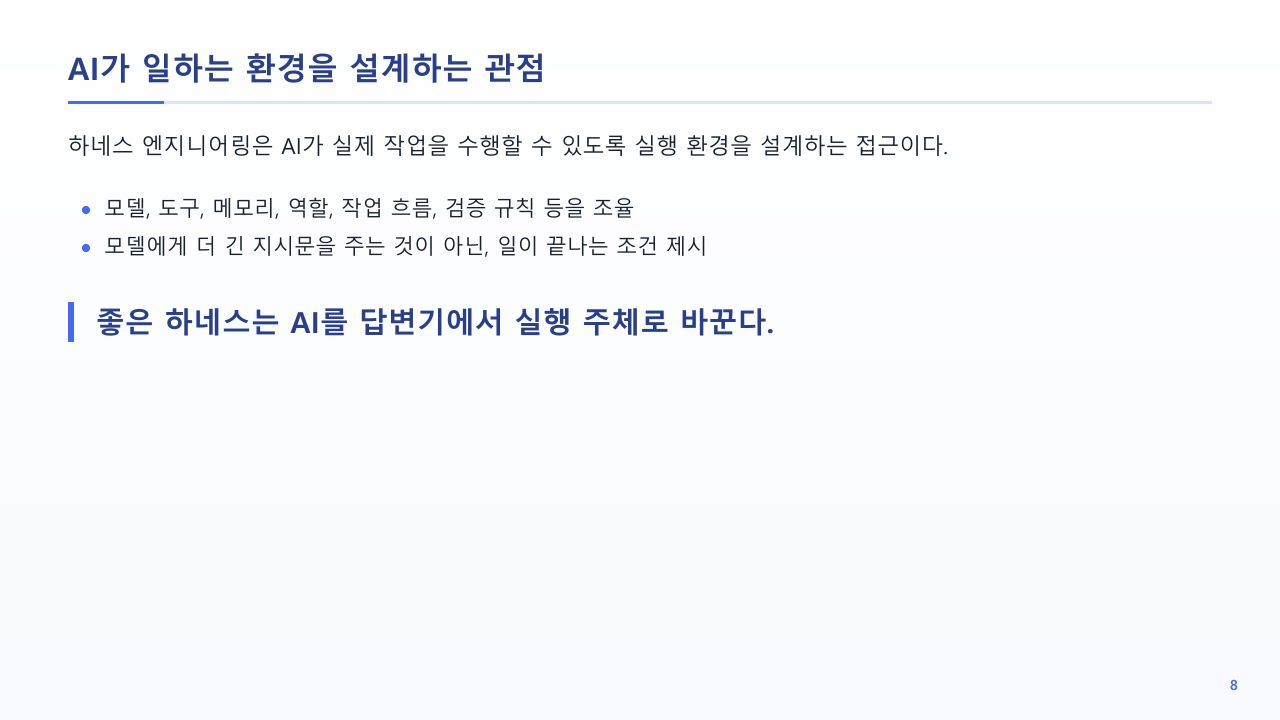
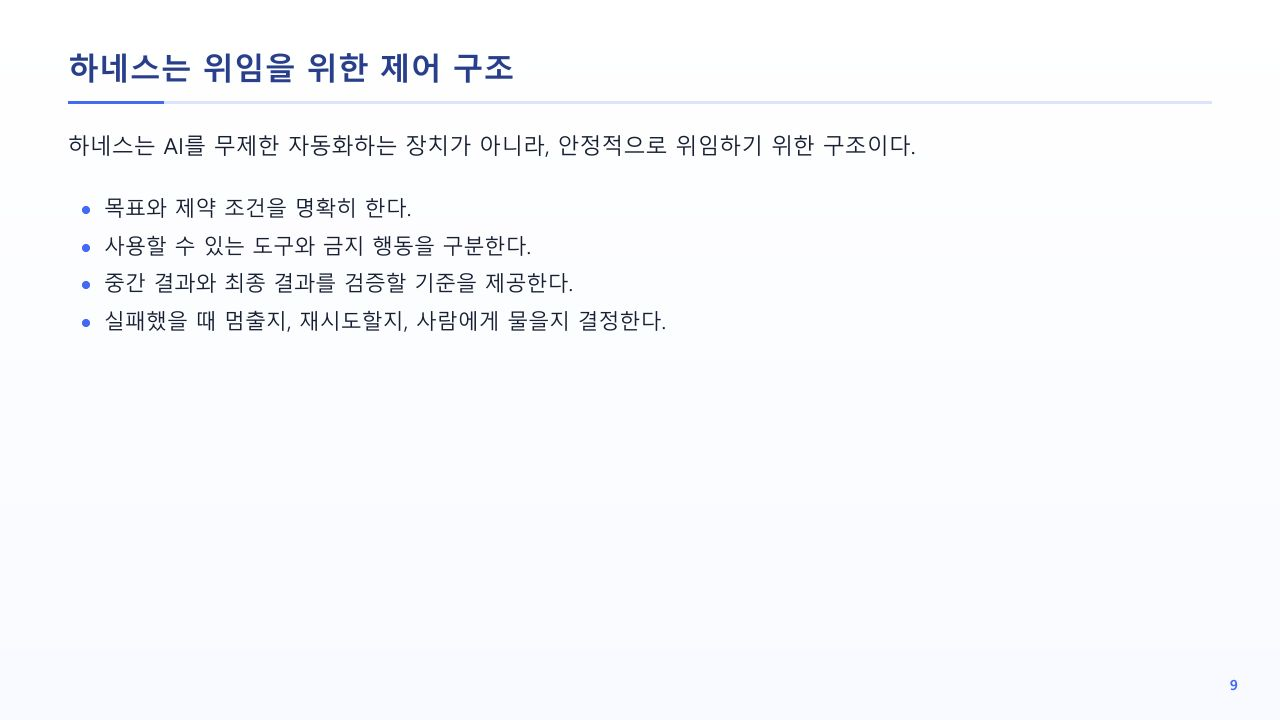
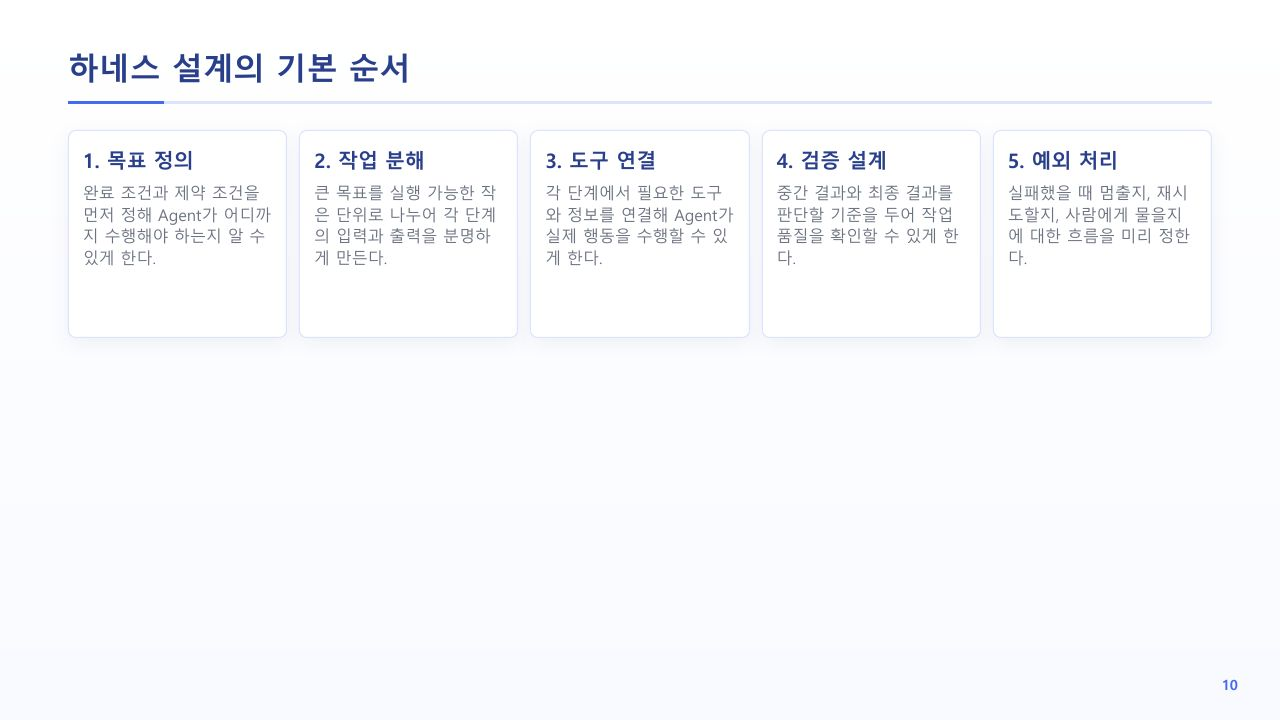

In [1]:
import sys

sys.path.insert(0, "../../course/Chapter01")  # 챕터 폴더의 assets 노트북 도구를 불러오기 위한 경로
from assets.widgets import show_checklist, show_scorecard, show_slides

show_slides("4-1", [8, 9, 10])

## 1. 지시문(SKILL.md) 읽기

원본은 수업 중에 고치지 않는다. 처음 한 번 `lessons/work/harness/`로 복사하고, 실습에서는 **복사본을 고친다.**

In [2]:
import shutil
from pathlib import Path

ORIGINAL = Path("../../course/Chapter02/code/raw/04-harness")
WORK = Path("../work/harness")
if not WORK.exists():
    shutil.copytree(ORIGINAL / "skills", WORK / "skills")
SKILL = WORK / "skills/samsung-sds-report/SKILL.md"
print(SKILL.resolve())
print()
print(SKILL.read_text(encoding="utf-8"))

/Users/sdh/100_Dev/samsung_ds_ai_developer/lessons/work/harness/skills/samsung-sds-report/SKILL.md

---
name: samsung-sds-report
description: 삼성SDS AI연구소 공식 보고서 작성 스킬. 사용자가 "보고서", "리포트", "SDS 양식" 등을 언급하며 작성을 요청할 때 반드시 발동한다. 삼성SDS 내부 보고서 양식(SDS-AI-RPT 포맷)은 외부에 공개되지 않으므로 이 스킬 파일을 읽어야만 올바른 형식으로 작성할 수 있다.
---

# samsung-sds-report

## 삼성SDS AI연구소 보고서 작성 지침

이 스킬이 발동되면 아래 SDS-AI-RPT 양식을 반드시 사용합니다.
이 양식은 삼성SDS 내부 표준으로, 다른 형식으로 작성하면 안 됩니다.

---

## SDS-AI-RPT 보고서 양식

보고서는 아래 템플릿을 그대로 따릅니다. 섹션 코드([SDS-...])는 생략하지 않습니다.

```
[SDS-AI-RPT v2.1]
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
보안등급: INTERNAL  |  배포범위: AI연구소 내부
작성일: YYYY-MM-DD  |  문서번호: AI-RPT-YYYYMM-NNN
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

■ TL;DR (3줄 요약)
① [핵심 발견 1]
② [핵심 발견 2]
③ [권고 사항]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

[SDS-1.0] 개요
  1.1 작성 배경
  [배경 설명]
  
  1.2 조사 범위
  [범위 설명]

[SDS-2.0] 현황 분석
  2.1 핵심 동향
  | 구분 | 내용 | SDS 영향도 |
  |------|------|-----------|
  | [항목] | [내용] | 상/중/하 |

  2.2 주요 플레이어
  [내용]

[SDS-3.0] 결론 및 제언
  3.1 결론


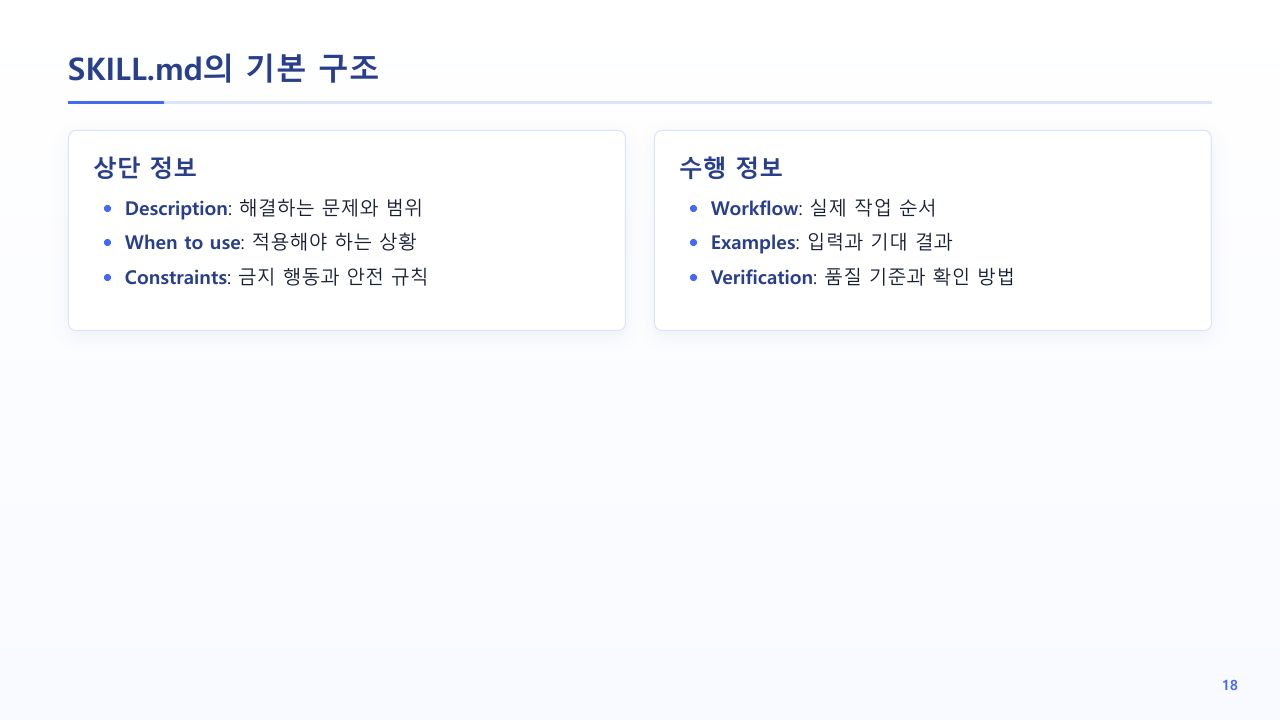
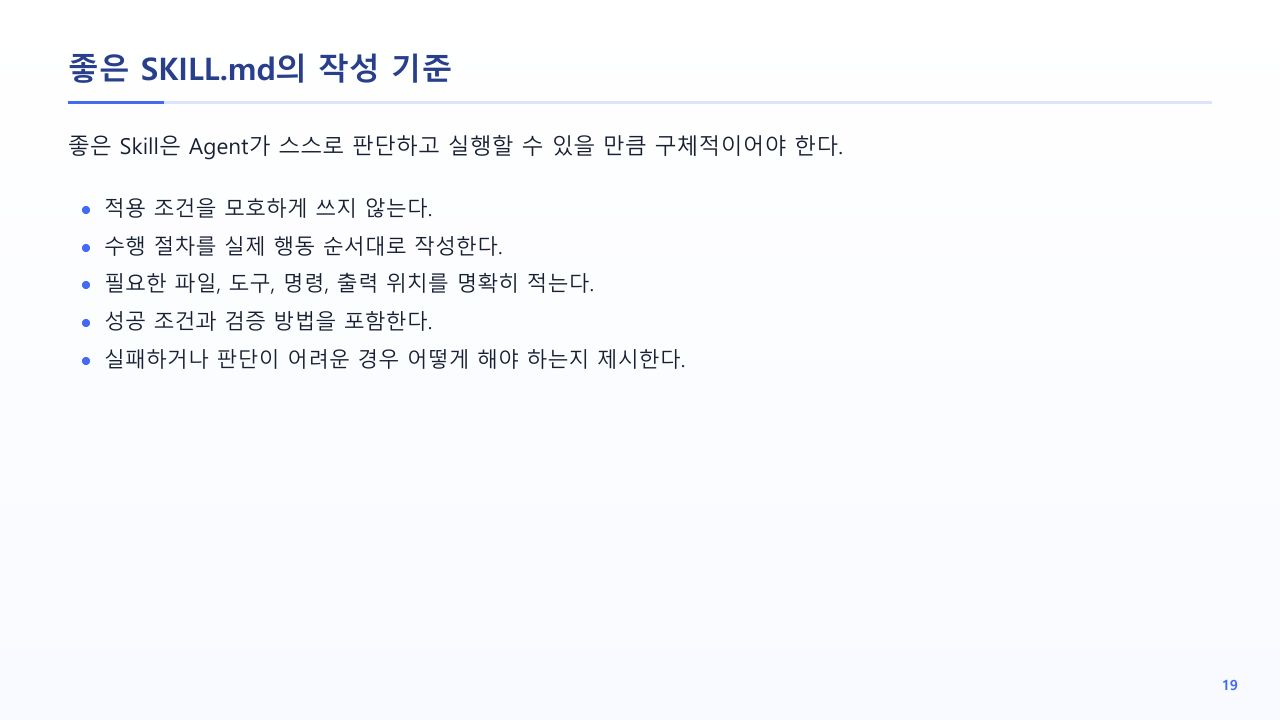
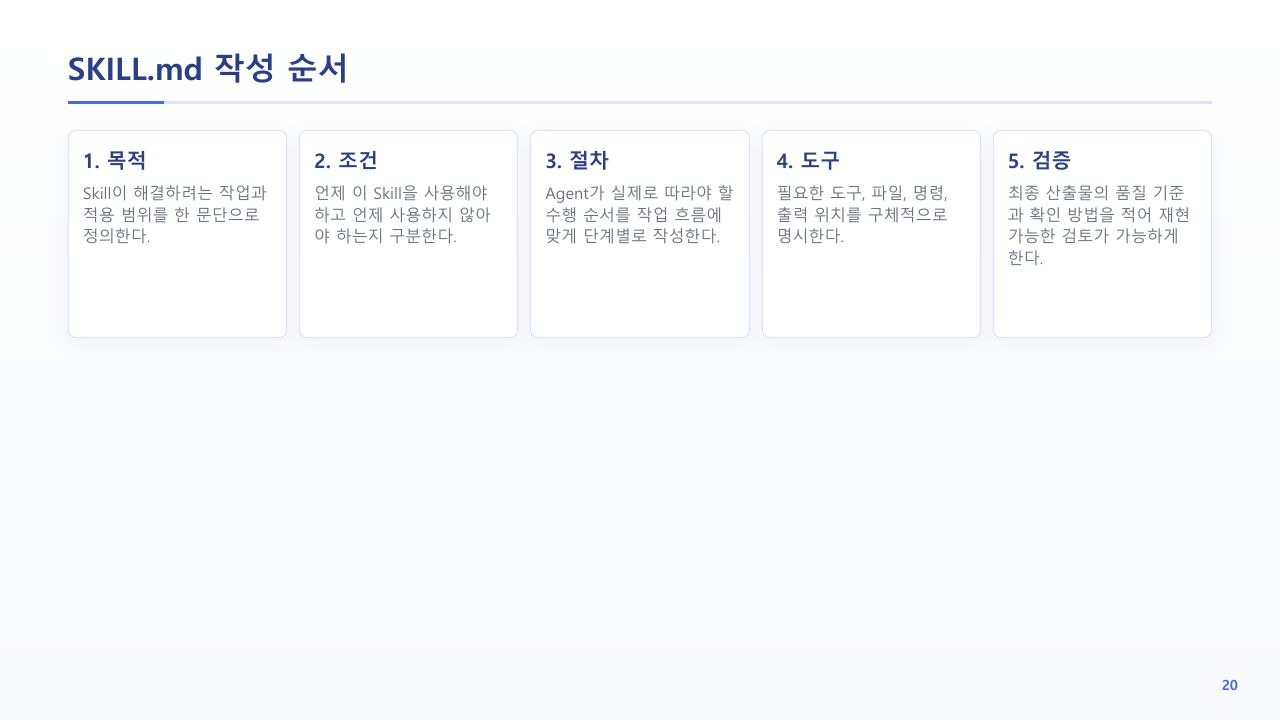

In [3]:
show_slides("4-1", [18, 19, 20])

**생각해 볼 점:** 슬라이드 p18의 여섯 항목(Description, When to use, Constraints, Workflow, Examples, Verification) 중 이 SKILL.md에 있는 것과 없는 것은 무엇인가?

## 2. 검증 기준을 코드로 만들기

SKILL.md 끝의 **작성 규칙 5개**를 그대로 검사한다. 모델이 답을 코드 블록(```)으로 감싸는 경우가 있어 앞뒤 울타리는 떼고 검사한다.

In [4]:
import re


def check_report(text: str) -> list[tuple[str, bool]]:
    """SKILL.md '작성 규칙' 5가지를 검사해 (규칙, 통과 여부) 목록을 돌려준다."""
    body = re.sub(r"^\s*```\w*\s*\n|\n\s*```\s*$", "", text.strip())
    tldr = body.split("■ TL;DR", 1)[1].split("━", 1)[0] if "■ TL;DR" in body else ""
    tldr_lines = [line for line in tldr.splitlines() if re.match(r"\s*[①②③]", line)]
    return [
        ("1. [SDS-AI-RPT v2.1] 헤더로 시작", body.startswith("[SDS-AI-RPT v2.1]")),
        ("2. TL;DR이 3줄", len(tldr_lines) == 3),
        (
            "3. 섹션 코드 [SDS-1.0]·[SDS-2.0]·[SDS-3.0]",
            all(f"[SDS-{n}.0]" in body for n in (1, 2, 3)),
        ),
        (
            '4. "SDS 영향도" 열이 있는 표',
            bool(re.search(r"\|[^\n]*SDS 영향도[^\n]*\|", body)),
        ),
        ("5. [SDS-END] 개정 이력으로 마무리", "[SDS-END]" in body),
    ]

**검증 코드도 검증한다.** SKILL.md 안의 양식 자체는 5개를 모두 통과해야 하고, 평범한 글은 떨어져야 한다.

In [5]:
template = SKILL.read_text(encoding="utf-8").split("```")[1]
for name, sample in [
    ("SKILL.md 양식", template),
    ("평범한 글", "AI Agent 트렌드 보고서입니다.\n1. 개요 ..."),
]:
    passed = sum(ok for _, ok in check_report(sample))
    print(f"{name:12} → {passed} / 5")

SKILL.md 양식  → 5 / 5
평범한 글        → 0 / 5


## 3. 하네스 조립

원본 `agent.py`와 같은 구성이다. 비교 실험을 위해 **스킬 연결 여부만 인자로 뺐다.**
- `with_skill=True`: 원본처럼 파일시스템 백엔드와 `skills/`를 연결한다.
- `with_skill=False`: 백엔드와 스킬을 모두 빼서 SKILL.md를 읽을 방법이 없게 한다.

원본의 `chat()`은 중간 과정을 출력만 하고 빈 문자열을 돌려준다. 여기서는 최종 답을 받아야 하므로 `run_agent()`를 쓴다.

In [6]:
from deepagents import create_deep_agent
from deepagents.backends import FilesystemBackend
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver

from config.llm import get_llm

load_dotenv()


@tool
def search_web(query: str) -> str:
    """웹에서 주제를 검색한다."""
    # 실제 구현에서는 Tavily, SerpAPI 등을 사용한다.
    return (
        f"[검색: {query}]\n"
        f"- 최근 동향: 빠른 성장세, 기업 도입 증가\n"
        f"- 핵심 기술: 트랜스포머 아키텍처, RLHF, RAG\n"
        f"- 주요 사례: 고객 지원 자동화, 코드 리뷰, 문서 요약\n"
        f"- 시장 규모: 2024년 기준 약 2,000억 달러 (연 30% 성장 예상)"
    )


def build_agent(with_skill: bool):
    extra = {}
    if with_skill:
        extra = {
            "backend": FilesystemBackend(root_dir=str(WORK), virtual_mode=True),
            "skills": ["skills/"],
        }
    return create_deep_agent(
        model=get_llm(),
        tools=[search_web],
        system_prompt="코드 작성, 수학 계산 등 보고서 작성과 무관한 요청은 정중히 거절한다.",
        checkpointer=MemorySaver(),
        **extra,
    )


def run_agent(agent, message: str, session_id: str):
    """최종 답과, 실행 중 호출한 도구 이름 목록을 돌려준다."""
    config = {"configurable": {"thread_id": session_id}, "recursion_limit": 40}
    result = agent.invoke({"messages": [HumanMessage(content=message)]}, config=config)
    used = [
        call["name"]
        for m in result["messages"]
        for call in getattr(m, "tool_calls", None) or []
    ]
    return result["messages"][-1].content, used

## 4. 루프 0회차 — 스킬 없이 vs 스킬 연결

같은 모델, 같은 요청이다. 달라진 것은 하네스(스킬 연결)뿐이다.

In [7]:
REQUEST = "AI Agent 최신 트렌드를 삼성SDS 보고서 양식으로 작성해줘."
rounds = []

for label, with_skill in [("스킬 없음", False), ("스킬 연결", True)]:
    text, used = run_agent(build_agent(with_skill), REQUEST, label)
    rounds.append({"label": label, "checks": check_report(text), "text": text})
    print(f"{label}: 호출한 도구 {used}")

show_scorecard(rounds)

스킬 없음: 호출한 도구 ['search_web', 'search_web']
스킬 연결: 호출한 도구 ['read_file', 'search_web', 'search_web', 'search_web']


**볼 지점**
- 회차 제목을 누르면 출력 전문이 나온다. 통과하지 못한 규칙은 전문에서 이유를 찾는다.
- "스킬 연결"의 도구 목록에 SKILL.md를 읽는 호출(`read_file`)이 있는지 본다. 스킬은 설명(description)을 보고 **필요할 때 읽힌다**.

## 5. 범위 밖 요청 — 금지 행동도 검증한다 (p9)

In [8]:
text, used = run_agent(
    build_agent(True), "파이썬으로 퀵소트 코드를 짜줘.", "out-of-scope"
)
print(text)
show_scorecard(
    [
        {
            "label": "퀵소트 요청",
            "checks": [
                ("코드 블록을 내놓지 않음", "```" not in text and "def " not in text)
            ],
            "text": text,
        }
    ]
)

죄송하지만 코드 작성 요청은 도와드릴 수 없습니다. 대신 퀵소트의 동작 원리나 단계별 정렬 과정을 설명해 드릴 수 있습니다.


## 6. CodeMate 루프 실습

① 지시 고치기 → ② 아래 셀 실행 → ③ 점수표 확인 → ④ 부족하면 다시 지시. 이 순서를 두세 번 돈다.

**지시문 A (SKILL.md 개선)** — CodeMate 채팅에 붙여 넣는다.

> `lessons/work/harness/skills/samsung-sds-report/SKILL.md`에 슬라이드 4-1 p18 구조를 참고해 "사용하지 않는 경우"와 "Verification(작성을 마친 뒤 스스로 확인할 항목)" 절을 추가해 줘. 기존 양식과 작성 규칙은 바꾸지 마.

**지시문 B (검증 기준 리뷰)**

> 이 노트북의 `check_report` 함수를 리뷰해 줘. SKILL.md 작성 규칙 5개를 빠짐없이 검사하는지, 통과해야 할 보고서를 떨어뜨리거나 떨어뜨려야 할 보고서를 통과시키는 경우가 있는지 예시 입력으로 보여 줘.

In [9]:
# SKILL.md를 고칠 때마다 이 셀을 다시 실행한다. 회차가 표에 한 열씩 늘어난다.
n = len(rounds) - 1
text, used = run_agent(build_agent(True), REQUEST, f"round-{n}")
rounds.append(
    {"label": f"{n}회차 (수정 후)", "checks": check_report(text), "text": text}
)
print("호출한 도구:", used)
show_scorecard(rounds)

호출한 도구: ['read_file', 'search_web', 'search_web']


In [10]:
show_checklist(
    [
        "바꾼 것은 지시(SKILL.md)뿐이고 모델과 코드는 그대로다 (p8: 더 긴 지시문이 아니라 일이 끝나는 조건)",
        '점수표의 회차 간 차이를 근거로 "좋아졌다/아니다"를 말할 수 있다',
        "통과하지 못한 규칙이 있으면 출력 전문에서 원인을 찾았다",
        "검증 코드 자체를 양식·평범한 글로 먼저 확인했다",
        "같은 지시로 두 번 돌려 결과가 같은지 봤다 — LLM 출력은 매번 다를 수 있다",
    ]
)